In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch, find_peaks
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import SGD, Adam


In [2]:
def preprocess_ecg(signal, fs = 360):
    f0 = 60.0  
    Q = 30.0
    b_notch, a_notch = iirnotch(f0, Q, fs)
    y_notch = filtfilt(b_notch, a_notch, signal)

    nyq = 0.5 * fs
    low = 0.5 / nyq
    high = 40.0 / nyq
    b_band, a_band = butter(4, [low, high], btype='band')
    y_clean = filtfilt(b_band, a_band, y_notch)
    return y_clean

In [3]:
def pan_tompkins_r_peaks(clean_signal, fs):
    diff_signal = np.diff(clean_signal)
    squared_signal = diff_signal ** 2

    window_width = int(0.15 * fs)
    integrated_signal = np.convolve(squared_signal, np.ones(window_width) / window_width, mode='same')

    min_distance = int(0.2 * fs)
    threshold = np.mean(integrated_signal)

    peaks, _ = find_peaks(integrated_signal, distance=min_distance, height=threshold)
    return peaks

In [4]:
def process_single_record(records, fs = 360):
    valid_symbols = ['N', 'L', 'R', 'V', '/']
    label_map = {'N': 0, 'L': 1, 'R': 2, 'V': 3, '/': 4}
    tolerance = 50
    left_offset = 90
    right_offset = 90

    X_final_list = []
    y_labels_list = []

    for record in records:
        try:
            df = pd.read_csv(f'datasets/train/{record}.csv')
        except:
            print("Cannot read file csv")
            continue
        # signal_mlii = df['MLII'].values
        if "'MLII'" in df.columns:
            signal_mlii = df["'MLII'"].values
        elif "MLII" in df.columns:
            signal_mlii = df["MLII"].values
        else:
            print("\n Cannot read MLII values")
            continue

        clean_mlii = preprocess_ecg(signal_mlii, fs)
        normalized_mlii = (clean_mlii - np.mean(clean_mlii)) / np.std(clean_mlii)

        r_peaks = pan_tompkins_r_peaks(clean_mlii, fs)

        ann_df = pd.read_csv(f'datasets/train/{record}annotations.txt', sep='\s+', engine='python')
        ann_df = ann_df[ann_df['#'].isin(valid_symbols)]

        valid_counts = 0
        for peak in r_peaks:
            if peak >= left_offset and (peak + right_offset) < len(normalized_mlii):

                closest_idx = (np.abs(ann_df['Sample'] - peak)).argmin()
                closest_ann = ann_df.iloc[closest_idx]

                if abs(closest_ann['Sample'] - peak) <= tolerance:
                    sym = closest_ann["#"]
                    label_int = label_map[sym]

                    segment = normalized_mlii[peak - left_offset : peak + right_offset]
                    
                    X_final_list.append(segment)
                    y_labels_list.append(label_int)
                    valid_counts += 1

        print(f"{record}.csv done - Have {len(r_peaks)}")

    X_proccessed = np.array(X_final_list)
    X_proccessed = np.expand_dims(X_proccessed, axis = -1)
    Y_proccessed = np.array(y_labels_list)


    return X_proccessed, Y_proccessed

<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Admin\AppData\Local\Temp\ipykernel_12724\1083527485.py:31: SyntaxWarning: invalid escape sequence '\s'
  ann_df = pd.read_csv(f'datasets/train/{record}annotations.txt', sep='\s+', engine='python')


In [5]:
records = []
for i in range(100, 125):
    records.append(str(i))
for j in range (200, 235):
    records.append(str(j))
X_data, y_labels = process_single_record(records)

print("X Shape: ", X_data.shape)
print("Y Shape: ", y_labels.shape)

100.csv done - Have 2273
101.csv done - Have 1872

 Cannot read MLII values
103.csv done - Have 2083

 Cannot read MLII values
105.csv done - Have 2674
106.csv done - Have 1931
107.csv done - Have 2135
108.csv done - Have 1840
109.csv done - Have 2528
Cannot read file csv
111.csv done - Have 2128
112.csv done - Have 2551
113.csv done - Have 1795
114.csv done - Have 1879
115.csv done - Have 1953
116.csv done - Have 2390
117.csv done - Have 1540
118.csv done - Have 2296
119.csv done - Have 1988
Cannot read file csv
121.csv done - Have 1880
122.csv done - Have 2476
123.csv done - Have 1518
124.csv done - Have 1620
200.csv done - Have 2659
201.csv done - Have 1949
202.csv done - Have 2131
203.csv done - Have 3056
Cannot read file csv
205.csv done - Have 2650
Cannot read file csv
207.csv done - Have 2217
208.csv done - Have 2932
209.csv done - Have 3013
210.csv done - Have 2647
Cannot read file csv
212.csv done - Have 2747
213.csv done - Have 3238
214.csv done - Have 2261
215.csv done - Hav

In [6]:
from sklearn.model_selection import train_test_split

classes, counts = np.unique(y_labels, return_counts=True)
print("Total classes of these datasets: ", dict(zip(classes, counts)))

valid_classes = classes[counts >= 5]

mask = np.isin(y_labels, valid_classes)
X_filtered = X_data[mask]
y_filtered = y_labels[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, 
    y_filtered, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_filtered 
)

print("Train dataset size: ", X_train.shape)
print("Test dataset size: ", y_test.shape)

Total classes of these datasets:  {0: 74569, 1: 8067, 2: 7251, 3: 6943, 4: 3618}
Train dataset size:  (80358, 180, 1)
Test dataset size:  (20090,)


### TensorFlow


In [7]:
model = Sequential([
    Conv1D(filters=32, kernel_size=5, activation='relu', input_shape=(180, 1)),
    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.5),

    Dense(5, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

print("Start Trainning")

history = model.fit(
                X_train, y_train,
                epochs=20,         
                batch_size=32,     
                validation_split=0.1
)

test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 176, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 88, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2816)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       180,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 180,805 (706.27 KB)

 Trainable params: 180,805 (706.27 KB)

 Non-trainable params: 0 (0.00 B)

Start Trainning
Epoch 1/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9085 - loss: 0.3075 - val_accuracy: 0.9802 - val_loss: 0.0832
Epoch 2/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9680 - loss: 0.1170 - val_accuracy: 0.9873 - val_loss: 0.0536
Epoch 3/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9722 - loss: 0.0995 - val_accuracy: 0.9883 - val_loss: 0.0518
Epoch 4/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9754 - loss: 0.0858 - val_accuracy: 0.9893 - val_loss: 0.0399
Epoch 5/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9761 - loss: 0.0791 - val_accuracy: 0.9905 - val_loss: 0.0402
Epoch 6/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9798 - loss: 0.0710 - val_accuracy: 0.9886 - val_loss: 0.0431
Epoch 7/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9798 - loss: 0.0706 - val_accuracy: 0.9900 - val_loss: 0.0396
Epoch 8/20
2261/2261 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9808 -

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
True label: N
Model's predictiom:       N
Confidence:             100.00%


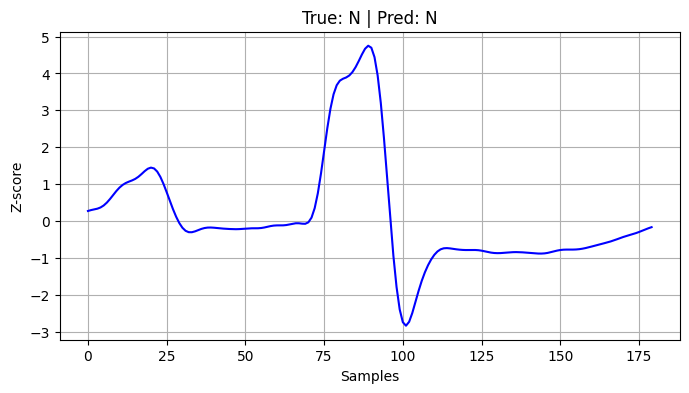

In [42]:
import numpy as np
import matplotlib.pyplot as plt

reverse_label_map = {
    0: 'N', 
    1: 'L', 
    2: 'R', 
    3: 'V', 
    4: '/'
}

random_idx = np.random.randint(0, len(X_test))
sample_ecg = X_test[random_idx]
true_label_int = y_test[random_idx]
true_label_str = reverse_label_map[true_label_int]


sample_batched = np.expand_dims(sample_ecg, axis=0)


predictions = model.predict(sample_batched) 
pred_label_int = np.argmax(predictions)     
pred_label_str = reverse_label_map[pred_label_int]
confidence = np.max(predictions) * 100     

print(f"True label: {true_label_str}")
print(f"Model's predictiom:       {pred_label_str}")
print(f"Confidence:             {confidence:.2f}%")


plt.figure(figsize=(8, 4))
plt.plot(sample_ecg, color='blue')
plt.title(f"True: {true_label_str} | Pred: {pred_label_str}")
plt.xlabel("Samples")
plt.ylabel("Z-score")
plt.grid(True)
plt.show()